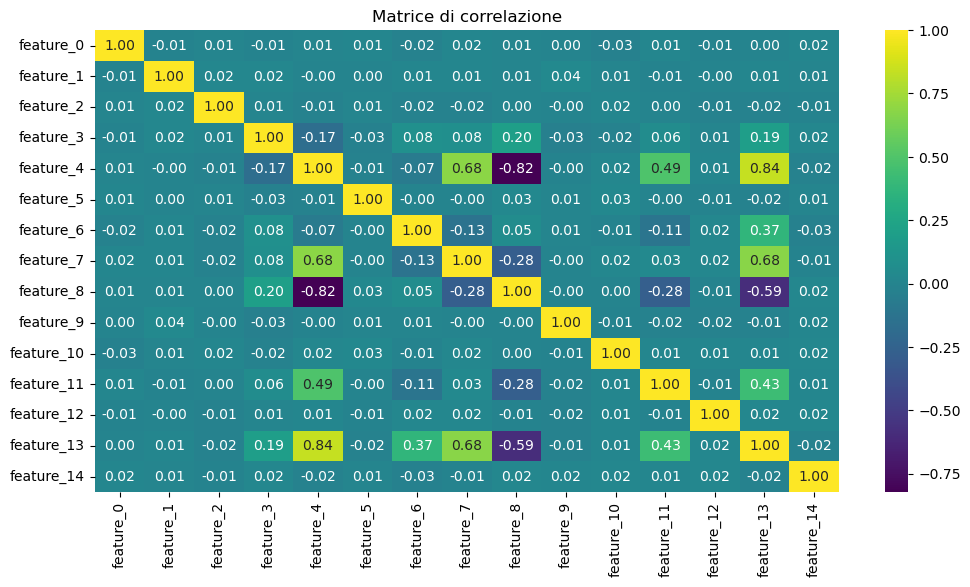

In [2]:
import pandas as pd

df = pd.read_csv("data.csv")

df.head()

# label binaria => classificazione binaria

X = df.drop(columns="class")
y = df["class"]

from sklearn.model_selection import train_test_split

X_train,X_test, y_train,y_test = train_test_split(X,y,test_size=0.05, stratify=y)

corr = X_train.corr()

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.heatmap(corr, cmap="viridis", fmt=".2f", annot=True)
plt.title("Matrice di correlazione")
plt.show()



In [3]:
threshold = 0.80

import numpy as np

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack()
print(pairs[pairs.abs() > threshold])

# creiamo una feature che sia una combinazione lineare
# delle tre

for dataset in [X_train,X_test]:
    dataset["feature_4_8_13"] = dataset[['feature_4', 'feature_8', 'feature_13']].mean(axis=1)

X_train = X_train.drop(columns=['feature_4', 'feature_8', 'feature_13'])
X_test = X_test.drop(columns=['feature_4', 'feature_8', 'feature_13'])


feature_4  feature_8    -0.823332
           feature_13    0.836369
dtype: float64


In [4]:
# scaling e feature selection

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.set_output(transform="pandas")

X_train_scaled = scaler.fit_transform(X_train, y_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X_train_scaled, y_train)

X_train_selected = selector.transform(X_train_scaled)
X_test_selected = selector.transform(X_test_scaled)


In [5]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC

n_samples = X_train_selected.shape[0]

param_grid = {
    'C' : [1, 1/ np.sqrt(n_samples)],
    'kernel' : ['rbf', 'poly'],
    'degree' : [3,4]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svc = SVC(random_state=42, probability=True)
grid = GridSearchCV(estimator=svc, param_grid=param_grid,cv=cv, scoring='accuracy', n_jobs=-1)

grid.fit(X_train_selected, y_train)
best_estimator = grid.best_estimator_
best_score = grid.best_score_
best_params = grid.best_params_

test_acc_svc = best_estimator.score(X_test_selected, y_test)
svc_proba = best_estimator.predict_proba(X_test_selected)
svc_pred = best_estimator.predict(X_test_selected)

print(f"Miglior classificatore: {best_estimator}\nAccuracy media in CV: {best_score}\nMigliori iperparametri:{best_params}")
print(f"Test Accuracy: {test_acc_svc}")


Miglior classificatore: SVC(C=1, probability=True, random_state=42)
Accuracy media in CV: 0.9245614035087719
Migliori iperparametri:{'C': 1, 'degree': 3, 'kernel': 'rbf'}
Test Accuracy: 0.9733333333333334


Epoch    1: 100%|██████████| 81/81 [00:00<00:00, 501.04it/s]


Train loss: 0.6618
Validation loss: 0.6143
Test loss: 0.6070 Accuracy:   0.91
Metrics:
precision_score:   0.91  recall_score:   0.91  f1_score:   0.91  


Epoch    2: 100%|██████████| 81/81 [00:00<00:00, 1597.48it/s]


Train loss: 0.5781
Validation loss: 0.5020
Test loss: 0.4739 Accuracy:   0.95
Metrics:
precision_score:   0.95  recall_score:   0.95  f1_score:   0.95  


Epoch    3: 100%|██████████| 81/81 [00:00<00:00, 1545.16it/s]


...

Train loss: 0.2276
Validation loss: 0.2084
Test loss: 0.1225 Accuracy:   0.97
Metrics:
precision_score:   0.97  recall_score:   0.97  f1_score:   0.97  


Epoch   22: 100%|██████████| 81/81 [00:00<00:00, 1688.91it/s]


Train loss: 0.2232
Validation loss: 0.2064
Test loss: 0.1212 Accuracy:   0.97
Metrics:
precision_score:   0.97  recall_score:   0.97  f1_score:   0.97  


Epoch   23: 100%|██████████| 81/81 [00:00<00:00, 1744.12it/s]


Train loss: 0.2260
Validation loss: 0.2059
Test loss: 0.1202 Accuracy:   0.97
Metrics:
precision_score:   0.97  recall_score:   0.97  f1_score:   0.97  


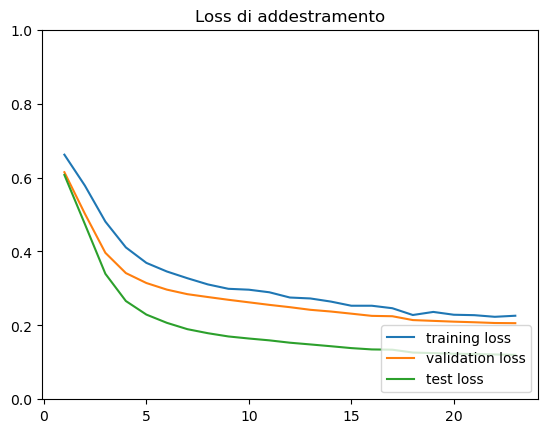

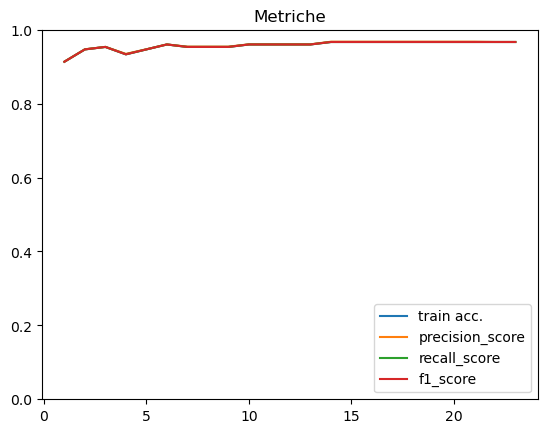

In [6]:
import torch
from torch import nn
import torchnn as tnn
from torch.utils.data import DataLoader, Dataset

X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(X_train_selected, y_train, test_size=0.10, stratify=y_train)

class Data(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(np.array(X), dtype=torch.float32)
        self.y = torch.tensor(np.array(y), dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, index):
        return self.X[index], self.y[index]


train_data = Data(X_train_nn, y_train_nn)
val_data = Data(X_val_nn, y_val_nn)
test_data = Data(X_test_selected, y_test)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

input_dim = X_train_nn.shape[1] #numero di features

class DataNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),

            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64,32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32,16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16,2) 
        )
    def forward(self,x):
        return self.layers(x) #tensore numerico in ingresso

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = DataNet(input_dim).to(device)

# bisogna addestrare il modello con gli iperparametri richiesti

import torch.optim as optim

optimizer = optim.RMSprop(model.parameters(),centered=True, lr=1e-4, weight_decay=0.001, momentum=0.1)
early_stopping = tnn.EarlyStopping(patience=5, min_delta=0.01)
loss_fn=nn.CrossEntropyLoss()

train_loss, validation_loss, test_loss, accuracy, test_metrics = tnn.train_test(
    model=model,
    optimizer=optimizer,
    device=device,
    #scheduler=scheduler,
    train_dataloader=train_loader,
    test_dataloader=test_loader,
    epochs=50,
    train_loss_fn=loss_fn,
    test_loss_fn=loss_fn,
    early_stopping=early_stopping,
    val_dataloader=val_loader
)

tnn.save_model(
    net=model,
    optimizer=optimizer,
    current_epoch=len(validation_loss),
    train_loss=train_loss,
    val_loss=validation_loss,
    test_loss=test_loss,
    accuracy=accuracy,
    metrics=test_metrics, 
    path="best_model.pt"

)

tnn.displayLosses(train_loss=train_loss, test_loss=test_loss, validation_loss=validation_loss)
tnn.displayMetrics(accuracy=accuracy, metrics=test_metrics)

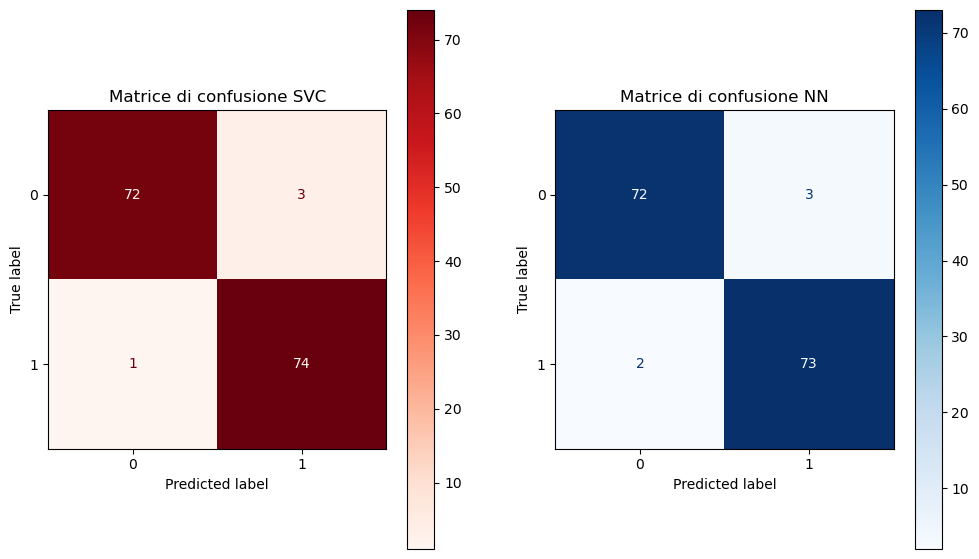

In [7]:

def evaluation(model, 
              test_loader, 
              device, 
              loss_fn):
    
    model.eval()
    nn_true, nn_pred, nn_prob,losses = [],[],[], []
    num_batches = len(test_loader)

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            logits=model(X_batch)
            prob = torch.softmax(logits, dim=1)
            pred = torch.argmax(prob, dim=1)

            losses.append(loss_fn(logits, y_batch).item())
            nn_true.extend(y_batch.cpu().numpy())
            nn_pred.extend(pred.cpu().numpy())
            nn_prob.extend(prob.cpu().numpy())

            nn_test_loss = sum(losses) / num_batches

    nn_true=np.array(nn_true)
    nn_pred=np.array(nn_pred)
    nn_prob=np.array(nn_prob)

    return nn_true, nn_pred, nn_prob, nn_test_loss, nn_test_loss

best_model, optimizer, checkpoint = tnn.load_model("best_model.pt", model=model, optimizer=optimizer, device=device)

nn_true, nn_pred, nn_prob, nn_test_loss, nn_test_loss = evaluation(best_model, test_loader, device, loss_fn)


# === Matrici di confusioni ===

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score, accuracy_score

fig, axes = plt.subplots(1,2, sharex=True, figsize=(12,7))

ConfusionMatrixDisplay.from_predictions(y_test, svc_pred, cmap='Reds', ax=axes[0])
axes[0].set_title("Matrice di confusione SVC")


ConfusionMatrixDisplay.from_predictions(nn_true, nn_pred, cmap='Blues', ax=axes[1])
axes[1].set_title("Matrice di confusione NN")

plt.show()



Accuracy in test per svc: 0.9733333333333334
Accuracy in test per nn: 0.9666666666666667


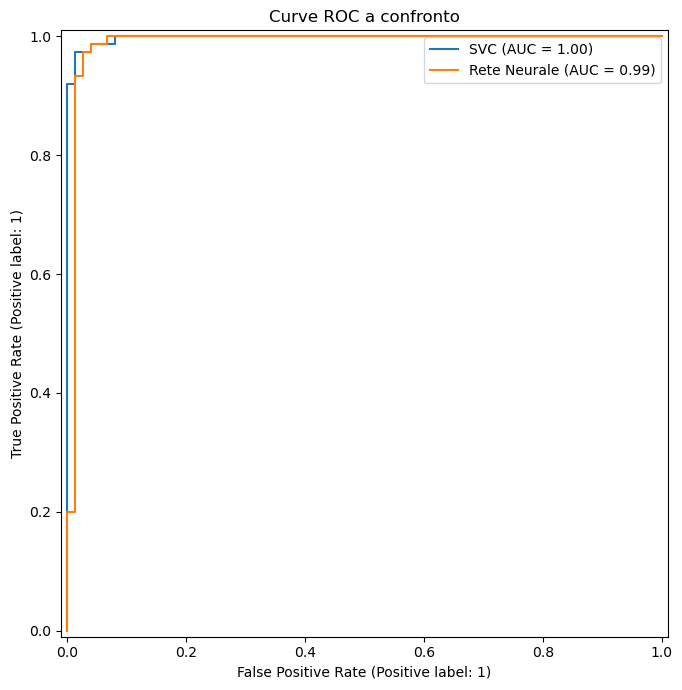

In [ ]:
# === ACCURACY ====

test_acc_nn = accuracy_score(nn_true, nn_pred)

print(f"Accuracy in test per svc: {test_acc_svc}")
print(f"Accuracy in test per nn: {test_acc_nn}")

# === ROC e AUC ====


auc_svc = roc_auc_score(y_test, svc_proba[:,1])
auc_nn = roc_auc_score(nn_true, nn_prob[:,1])

fig,ax = plt.subplots(figsize=(12,7))

RocCurveDisplay.from_predictions(y_test,svc_proba[:,1], ax=ax, name="SVC")
RocCurveDisplay.from_predictions(nn_true, nn_prob[:,1], ax=ax, name="Rete Neurale")

ax.set_title("Curve ROC a confronto")
ax.legend()
plt.tight_layout()
plt.show()